# 1. Modifiers & Induced Expression

Welcome to **Tutorial 2**! In Tutorial 1 you built and modified models with **substrates** and **products**, but we left the **Modifiers** column empty in `reactions.csv`. Now let's unlock modifiers — one of the most important building blocks for realistic biological models!

## What are modifiers?

Suppose you want to model the transcription factor **NF-κB** (`NFkB`) inducing expression of its target gene **IκB** (`IkB`).

It is tempting to draw a simple arrow straight from `NFkB` to `IkB`, just like `A → B` in Tutorial 1:

```{figure} ../images/nfkb-substrate-wrong.svg
:alt: Incorrect diagram showing NFkB turning into IkB as a substrate
:width: 100%

Why `NFkB → IkB` is biologically wrong: it says `NFkB` is *consumed* to make `IkB`.
```

While `IkB` would go up when `NFkB` goes up, that diagram literally means **`NFkB` turns into `IkB`** — which is *not* what happens in a cell! `NFkB` is **not used up** when it induces transcription of `IkB` (just like mRNA is not used up when it is translated into protein).

Instead, we need `NFkB` to control the **rate** of `IkB` production *without* being a substrate. That is exactly what a **modifier** does!

```{figure} ../images/nfkb-modifier-correct.svg
:alt: Correct modifier notation showing NFkB promoting IkB expression with a circle on a stick, and inhibition with a flat T-bar
:width: 100%

**Left:** Promotion (circle on a stick) — `NFkB` increases the expression rate of `IkB` without being consumed. **Right:** Inhibition (flat T-bar) — as `A` increases, the expression rate of `B` decreases.
```

:::{important} Modifiers point to arrows, not nodes!
Notice that the modifier connects to the **reaction arrow**, not directly to the `IkB` box. `NFkB` doesn't turn into `IkB` — it controls *how fast* the expression reaction runs. Keeping this distinction clear becomes essential as models grow larger!
:::

---

## Our first model with a modifier (`NFkB` inducing `IkB`)

Remember every model is built from **3 CSV files**:
1. **`reactionsMod.csv`** — puts `NFkB` in the **`Modifiers`** column (leaving `Substrate` empty, since `IkB` is synthesized anew!).
2. **`ratelawsMod.csv`** — defines a new kinetic law called `Induced Expression`:
   ```text
   {k1} * ([Mod1] / ({k2} + [Mod1]))
   ```
3. **`parametersMod.csv`** — sets numerical values for `k1_IkBexp` and `k2_IkBexp`.

### Making sense of the `Induced Expression` maths

That rate law looks intimidating in a CSV cell, so let's write it out cleanly as mathematics:

$$
\text{Rate} = k_1 \cdot \frac{[\text{Mod1}]}{k_2 + [\text{Mod1}]}
$$

Here:
- **$k_1$** is the **maximum expression rate** (bigger $k_1$ → more `IkB` produced at full activation).
- **The fraction $\frac{[\text{Mod1}]}{k_2 + [\text{Mod1}]}$** scales smoothly between **$0$** and **$1$** depending on how much modifier (`NFkB`) is present!
  - When `NFkB` is **huge** (say `99999`), $\frac{99999}{k_2 + 99999} \approx 1$, so $\text{Rate} \approx k_1 \times 1 = k_1$.
  - When `NFkB` is **tiny** (near `0`), $\frac{0}{k_2 + 0} = 0$, so $\text{Rate} \approx 0$.

Let's visualize this rate law in Julia right now (click **⚡ Compute** at the top of the page if you haven't already!).

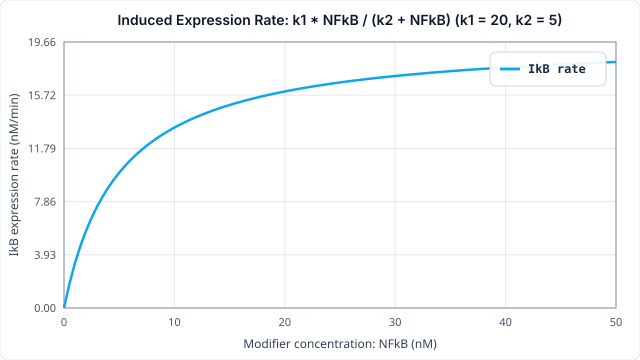

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()

# Visualise the Induced Expression rate law for k1 = 20, k2 = 5
k1 = 20.0
k2 = 5.0
nfkb_vals = 0.0:0.5:50.0
rates = [k1 * (x / (k2 + x)) for x in nfkb_vals]

plot(
    nfkb_vals,
    rates,
    label = "IkB rate",
    xlabel = "Modifier concentration: NFkB (nM)",
    ylabel = "IkB expression rate (nM/min)",
    title = "Induced Expression Rate: k1 * NFkB / (k2 + NFkB)  (k1 = 20, k2 = 5)",
    lw = 2.5,
)

### Check your intuition on $k_1$ and $k_2$

Suppose **$k_1 = 20$** and **$k_2 = 5$**. Work out these three quick questions before checking the answers:

1. **If there is almost no modifier (`NFkB ≈ 0`), what is the approximate rate of expression?**
   ````{admonition} 💡 Hint
   :class: dropdown tip
   Plug `Mod1 = 0` into the numerator of $\frac{[\text{Mod1}]}{k_2 + [\text{Mod1}]}$.
   ````
   ````{admonition} ✅ Reveal Answer
   :class: dropdown note
   **Basically `0`!** Because $k_1 \times \frac{0}{5 + 0} = 20 \times 0 = 0$, regardless of what $k_1$ is.
   ````

2. **If there is a huge amount of modifier (`NFkB = 99999`), what is the approximate rate of expression?**
   ````{admonition} 💡 Hint
   :class: dropdown tip
   What is $\frac{99999}{5 + 99999}$ close to?
   ````
   ````{admonition} ✅ Reveal Answer
   :class: dropdown note
   **Basically `20`!** The fraction is $\frac{99999}{100004} \approx 0.99995 \approx 1$, so the rate approaches $k_1 \times 1 = 20$ (the maximum expression rate).
   ````

3. **If there is exactly `5 nM` of modifier (`NFkB = 5`, equal to $k_2$), what is the rate of expression?**
   ````{admonition} 💡 Hint
   :class: dropdown tip
   Substitute `Mod1 = 5` and `k2 = 5` into $\frac{[\text{Mod1}]}{k_2 + [\text{Mod1}]}$ first!
   ````
   ````{admonition} ✅ Reveal Answer
   :class: dropdown note
   **`10` (half of $k_1$)!** When $[\text{Mod1}] = k_2$, the fraction is $\frac{5}{5 + 5} = \frac{1}{2}$, so $\text{Rate} = 20 \times \frac{1}{2} = 10$.

   That's the intuitive meaning of **$k_2$**: it is the modifier concentration that produces **half-maximal** expression!
   ````

---

## Create the three modifier CSV files

Run the cell below to save `reactionsMod.csv`, `ratelawsMod.csv`, and `parametersMod.csv` (with max expression $k_1 = 20$ and half-max concentration $k_2 = 5$) into your workspace!

In [2]:
write("reactionsMod.csv", """Substrate,Products,Kinetic Law,Modifiers,Parameters
,IkB,Induced Expression,NFkB,k1_IkBexp k2_IkBexp
""")

write("ratelawsMod.csv", """Rate Law Name,Rate Law Definition
Induced Expression,{k1} * ([Mod1] / ({k2} + [Mod1]))
""")

write("parametersMod.csv", """Parameter,Value
k1_IkBexp,20
k2_IkBexp,5
""")

println("Saved reactionsMod.csv, ratelawsMod.csv, and parametersMod.csv!")
show(CSV.read("reactionsMod.csv", DataFrame); allcols=true)

Saved reactionsMod.csv, ratelawsMod.csv, and parametersMod.csv!
1×5 DataFrame
 Row │ Substrate  Products  Kinetic Law         Modifiers  Parameters
     │ Missing    String3   String31            String7    String31
─────┼──────────────────────────────────────────────────────────────────────
   1 │ missing    IkB       Induced Expression  NFkB       k1_IkBexp k2_IkBexp


---

## Challenge: Run your first model with a modifier!

The cell below contains the **original Tutorial 1 Toy Model runner code**.

Adapt it yourself to:
1. Point to `reactionsMod.csv`, `parametersMod.csv`, and `ratelawsMod.csv` (and generate `modModel.jl`).
2. Set the initial conditions to **10 nM of `NFkB`** and **0 nM of `IkB`** *(be careful to check the order of species in `syms`!)*.
3. Run the simulation for 60 minutes and plot the result! What does **`IkB`** do over time? What does **`NFkB`** do over time?

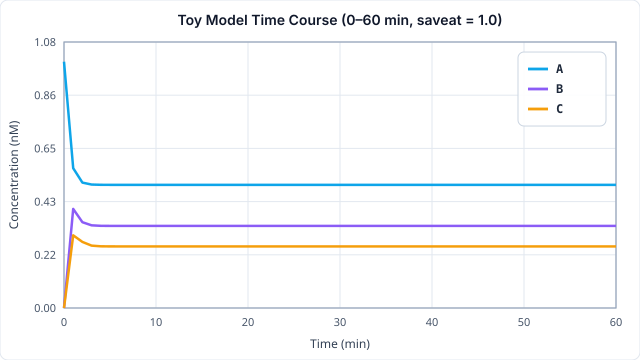

In [3]:
# Original Tutorial 1 runner code — edit this cell to run the NFkB/IkB modifier model!
reactionsFile = "reactions.csv"
rateLawsFile = "ratelaws.csv"
parametersFile = "parameters.csv"
thisModelName = "toyModel.jl"
maxTimeTC = 60.0

run(`python3 csv2model-multiscale.py $reactionsFile $parametersFile $rateLawsFile $thisModelName`)
include(thisModelName)
include("variableNames.jl")
println("Species order (syms): ", syms)

y0 = [1.0, 0.0, 0.0]
prob = ODEProblem(ODEFunction(toyModel), y0, (0.0, maxTimeTC))
sol = solve(prob, abstol=1e-5, reltol=1e-3)

plot(
    sol,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Modifier Model",
    lw = 2.5,
)

```{admonition} 💡 Hint
:class: dropdown tip

1. Update the four filenames (`reactionsMod.csv`, `ratelawsMod.csv`, `parametersMod.csv`, `modModel.jl`) and update `ODEFunction(toyModel)` → `ODEFunction(modModel)`.
2. Check the printed `syms` order! `CSV2Model` lists products (`IkB`) before modifiers (`NFkB`), so `syms` is `["IkB", "NFkB"]` — meaning `y0` has **2** entries: `[IkB_0, NFkB_0]`, NOT `[NFkB_0, IkB_0]`!
```

````{admonition} ✅ Reveal Solution
:class: dropdown note

1. Change the three CSV filenames to `reactionsMod.csv`, `ratelawsMod.csv`, and `parametersMod.csv`, and set `thisModelName = "modModel.jl"`.
2. Change `ODEFunction(toyModel)` to `ODEFunction(modModel)`.
3. Because `syms` is `["IkB", "NFkB"]`, set `y0 = [0.0, 10.0]` (0 nM `IkB`, 10 nM `NFkB`).
4. When you run it, **`NFkB` stays flat at 10 nM** (it is a modifier, not consumed!) while **`IkB` increases forever in a straight line** (at rate $20 \times \frac{10}{5 + 10} = 13.33\text{ nM/min}$) because nothing degrades `IkB` yet!

```julia
reactionsFile = "reactionsMod.csv"
rateLawsFile = "ratelawsMod.csv"
parametersFile = "parametersMod.csv"
thisModelName = "modModel.jl"
maxTimeTC = 60.0

run(`python3 csv2model-multiscale.py $reactionsFile $parametersFile $rateLawsFile $thisModelName`)
include(thisModelName)
include("variableNames.jl")
println("Species order (syms): ", syms)

y0 = [0.0, 10.0]  # [IkB, NFkB]
prob = ODEProblem(ODEFunction(modModel), y0, (0.0, maxTimeTC))
sol = solve(prob, abstol=1e-5, reltol=1e-3)

plot(
    sol,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "NFkB Inducing IkB (No Degradation Yet)",
    lw = 2.5,
)
```
````

---

## Dealing with errors

Don't worry when you get errors trying something new — it happens to everyone, and Julia error messages can look intimidating at first!

**Most errors boil down to typos.** Look at the deliberate bug in the cell below, run it, and read the very top line of the error message:
- It says **`UndefVarError: sols not defined`**, and the stack trace points right to the line that failed!
- Can you spot the typo and fix it?

In [ ]:
# Run this cell first to see the error message, then fix the typo!
plot(sols, label=permutedims(syms), lw=2.5)

```{admonition} 💡 Hint
:class: dropdown tip

Look at the exact variable name in the error: `UndefVarError: sols not defined`. What did we actually name our solution variable in the cell above?
```

````{admonition} ✅ Reveal Solution
:class: dropdown note

Earlier we saved the ODE solution as **`sol`** (singular), but the plotting line asked for **`sols`** (plural)! Making the spelling consistent fixes the error immediately:

```julia
plot(sol, label=permutedims(syms), lw=2.5)
```
````

Now that you've mastered modifiers and error messages, head to **[2. Modifier Challenges (NF-κB / IκB)](./02-modifier-challenges.ipynb)** to build a realistic feedback pathway!